# Passaggio 6: simulazione della versione A con i costi (solo train)

**Obiettivo.** Rispondere alla domanda che decide il resto del progetto: i 6.8 punti base lordi per trade del Passaggio 4 sopravvivono ai costi di trading? Il motore è nel modulo [backtest.py](backtest.py); parte dai trade di `signals_10pairs_train.csv` e applica versione, costi e capitale.

**Regole fissate prima di guardare i risultati**
- importo fisso di 10.000 dollari per gamba, uguale sulle due gambe, senza leva; tutto chiuso a fine giornata;
- un trade ha 4 operazioni (apertura e chiusura di due gambe): costo del trade = 4 x costo per operazione;
- scenari di costo 0, 2, 5 e 10 punti base per operazione; **scenario realistico = 5** (decisione di Bea);
- capitale del portafoglio = 20.000 dollari per coppia (10 coppie = 200.000), i giorni senza trade valgono 0;
- Sharpe senza tasso privo di rischio, perché i trade durano ore e i dati sono 3 mesi;
- **il test (dal 17 settembre) non si legge**: il motore rifiuta trade dopo il 16 settembre.

Limite da ricordare: i risultati sono sul train, su cui sono stati scelti i parametri del segnale, quindi sono ottimistici.

## 1. Dati e controllo di coerenza

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from backtest import (load_trades, trading_days, apply_version, random_decisions, add_costs, daily_pnl, summary,
                      breakeven_cost, by_cost, by_group, entry_window, COST_SCENARIOS, MAIN_COST, OPERATIONS_PER_TRADE)

pd.options.display.float_format = "{:,.2f}".format
trades = load_trades()
days = trading_days()
print(len(trades), "trade,", len(days), "giorni di train,", trades.pair.nunique(), "coppie")

# A costo zero il motore deve riprodurre i numeri del Passaggio 4: 624 trade, 6.8 bps lordi
a0 = add_costs(apply_version(trades, "A"), 0)
assert len(a0) == 624 and round(a0.gross_bps.mean(), 1) == 6.8, "i numeri non tornano con il Passaggio 4"
assert np.allclose(a0.net_bps, a0.gross_bps)
print("controllo ok: 624 trade, guadagno lordo medio", round(a0.gross_bps.mean(), 2), "bps")

624 trade, 64 giorni di train, 10 coppie
controllo ok: 624 trade, guadagno lordo medio 6.77 bps


## 2. Versione A per scenario di costo

In [2]:
A = apply_version(trades, "A")
table = by_cost(A, days)
table[["trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "pnl_usd", "total_return", "sharpe", "max_drawdown"]]

,trade,gross_bps,net_bps,se_bps,win_rate,profit_factor,pnl_usd,total_return,sharpe,max_drawdown
cost_bps_per_operation,,,,,,,,,,
0,624.00,6.77,6.77,2.10,0.59,1.46,"4,226.20",0.02,6.51,-0.00
2,624.00,6.77,-1.23,2.10,0.53,0.93,-765.80,-0.00,-1.19,-0.01
5,624.00,6.77,-13.23,2.10,0.38,0.47,"-8,253.80",-0.04,-12.34,-0.04
10,624.00,6.77,-33.23,2.10,0.17,0.16,"-20,733.80",-0.10,-26.96,-0.10


In [3]:
be = breakeven_cost(A)
print(f"Costo di pareggio: {be:.2f} bps per operazione ({OPERATIONS_PER_TRADE * be:.2f} bps per trade).")
print(f"Scenario realistico ({MAIN_COST} bps): costo {OPERATIONS_PER_TRADE * MAIN_COST} bps per trade contro {A.gross_bps.mean():.2f} bps lordi.")

Costo di pareggio: 1.69 bps per operazione (6.77 bps per trade).
Scenario realistico (5 bps): costo 20 bps per trade contro 6.77 bps lordi.


## 3. Da dove viene il guadagno (scenario realistico)

In [4]:
by_group(A, "pair")

,trade,gross_bps,net_bps,se_bps,win_rate
pair,,,,,
BAC-PNC,62,-3.82,-23.82,6.58,0.39
BNY-GS,51,9.60,-10.40,8.47,0.51
CSX-UNP,61,6.81,-13.19,4.16,0.38
HD-LOW,65,4.39,-15.61,4.13,0.37
ITW-OTIS,54,3.23,-16.77,5.72,0.43
KO-PEP,68,3.53,-16.47,4.86,0.29
MA-V,75,7.54,-12.46,2.51,0.23
MCD-YUM,64,9.66,-10.34,6.89,0.47
PYPL-XYZ,60,29.60,9.60,13.98,0.58


In [5]:
by_group(A, entry_window(A))

,trade,gross_bps,net_bps,se_bps,win_rate
finestra,,,,,
apertura (15-30 min),271,12.44,-7.56,3.97,0.44
dopo i 30 min,353,2.42,-17.58,2.09,0.33


In [6]:
by_group(A, "exit_reason")

,trade,gross_bps,net_bps,se_bps,win_rate
exit_reason,,,,,
fine_giornata,42,-16.07,-36.07,4.46,0.07
rientro,301,37.11,17.11,1.65,0.69
stop,14,-38.09,-58.09,7.58,0.00
tempo,267,-21.48,-41.48,3.52,0.09


Il costo di pareggio per le sole entrate dopo i 30 minuti (le altre sono il rientro del gap della notte, vedi Passaggio 4):

In [7]:
w = entry_window(A)
for name, sub in A.groupby(w):
    print(f"{name}: {len(sub)} trade, lordo {sub.gross_bps.mean():.2f} bps, costo di pareggio {breakeven_cost(sub):.2f} bps per operazione")

apertura (15-30 min): 271 trade, lordo 12.44 bps, costo di pareggio 3.11 bps per operazione
dopo i 30 min: 353 trade, lordo 2.42 bps, costo di pareggio 0.60 bps per operazione


## 4. Curva di capitale (scenario realistico)

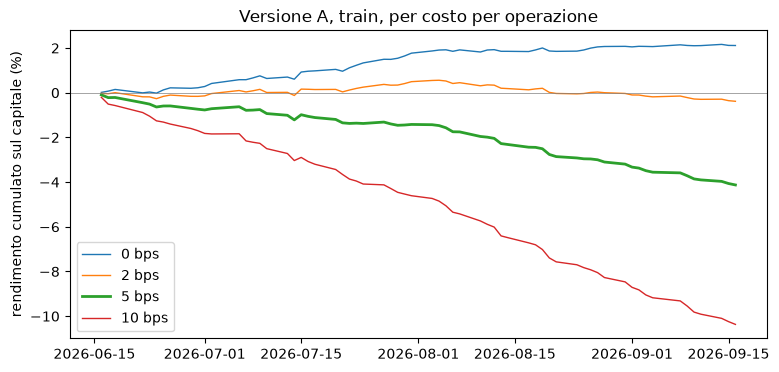

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
for c in COST_SCENARIOS:
    d = daily_pnl(add_costs(A, c), days)
    ax.plot(d.index, d.equity * 100, label=f"{c} bps", lw=2 if c == MAIN_COST else 1)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("rendimento cumulato sul capitale (%)"); ax.set_title("Versione A, train, per costo per operazione"); ax.legend()
plt.show()

## 5. Prova del motore sulle versioni B e C (decisioni finte)

Serve solo a verificare che il motore funzioni quando arriveranno le decisioni dell'agente: blocco casuale del 20% dei segnali. **Non vanno interpretati**: non c'è nessun agente.

In [9]:
dec = random_decisions(trades, p_block=0.2, seed=0)
B = apply_version(trades, "B", dec)
print(len(B), "trade su", len(trades), "(bloccati", dec.decision.eq("blocca").sum(), ")")
print("B, finti, a", MAIN_COST, "bps:", round(add_costs(B, MAIN_COST).net_bps.mean(), 2), "bps netti")

# senza decisioni, B e C bloccano tutto? Qui il motore chiede le decisioni: la regola "ricerca fallita = blocca" è nel Passaggio 5
try:
    apply_version(trades, "B")
except ValueError as e:
    print("ok:", e)
try:
    apply_version(trades, "C", dec.assign(decision="segui"))
except NotImplementedError as e:
    print("ok:", e)

502 trade su 624 (bloccati 122 )
B, finti, a 5 bps: -11.68 bps netti
ok: la versione B richiede le decisioni dell'agente
ok: versione C: serve la simulazione con direzione scelta dall'agente


## 6. Cosa ci dicono i risultati

Train, 624 trade, 64 giorni, versione A. Il controllo di coerenza torna: a costo zero 624 trade e 6.77 bps lordi, come nel Passaggio 4.

- **Con i costi la versione A perde.** Il costo di pareggio è **1.69 bps per operazione** (6.77 bps per trade). A 2 bps il guadagno netto è -1.2 bps per trade, a 5 bps (scenario realistico) -13.2 bps, a 10 bps -33.2 bps. Rendimento sul capitale in 64 giorni: +2.1% senza costi, -4.1% a 5 bps. Lo Sharpe a costo zero (6.5) non va letto: è lordo, su 64 giorni e sugli stessi dati su cui sono stati scelti i parametri.
- **Solo i rientri guadagnano.** Rientro: 301 trade a +37.1 bps lordi. Tempo massimo (267 trade, -21.5), fine giornata (42, -16.1) e stop (14, -38.1) perdono. Il tempo massimo di 90 minuti non è ottimizzato: è il primo parametro da rivedere.
- **Il guadagno è nel gap della notte.** Entrate nei minuti 15-30: 271 trade, 12.4 bps lordi, costo di pareggio 3.1 bps per operazione. Dopo i 30 minuti: 353 trade, 2.4 bps lordi, costo di pareggio 0.6 bps. Anche togliendo la parte "gap", il resto non copre nessun costo realistico.
- **Una sola coppia è netta positiva a 5 bps: PYPL-XYZ** (+9.6 bps netti, ma errore standard 14 bps, 60 trade). Tutte le altre sono negative; BAC-PNC e TFC-USB sono negative anche al lordo.
- **Conseguenza per il progetto.** Con questi segnali e questi costi nessuna versione (A, B o C) può essere in guadagno netto, se l'agente non cambia radicalmente la qualità dei trade. Un agente che blocca può al massimo togliere i trade perdenti: per pareggiare servirebbero blocchi quasi perfetti. Il confronto tra A, B e C si potrà comunque fare al **lordo e a costi bassi (0-2 bps)**, dichiarando che a costi realistici la strategia di base non è redditizia. Prima di costruire l'agente conviene decidere se cambiare le regole (tempo massimo, ingressi dopo i 30 minuti, soglie più alte per avere meno trade e più grandi), sempre sul train.

**Limiti.** Costi per operazione stimati, non misurati; nessun costo di prestito dei titoli; il 18% dei trade è eseguito a un prezzo vecchio; risultati sul train, quindi ottimistici; le versioni B e C non sono ancora simulate (decisioni finte nella sezione 5, non interpretabili).